In [1]:
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timezone
import os
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

import database
import all_features

# Import data from the DB

In [2]:
df = all_features.get_all_features()

In [3]:
df

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9,6.238046,1.965397,3.706547,5.122923,0.591065,NaN,NaN,NaN,NaN,NaN,4.2,0.3,4.3,0.4,4.5,0.6,5.7,1.8
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2,6.133539,1.963325,3.718834,5.122881,0.623249,-0.213873,-0.004760,0.028695,-0.000098,0.3,4.2,0.0,4.4,0.2,4.6,0.4,5.7,1.5
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2,6.171726,1.960487,3.707315,5.123159,0.623249,0.091912,-0.006513,-0.026175,0.000641,0.0,4.3,0.1,4.3,0.1,4.9,0.7,5.7,1.5
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3,6.286905,1.959596,3.677789,5.123038,0.633468,0.303704,-0.002050,-0.065725,-0.000279,0.1,4.4,0.1,4.5,0.2,5.0,0.7,5.7,1.4
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4,6.200577,1.958034,3.664172,5.122078,0.643453,-0.180269,-0.003590,-0.030869,-0.002207,0.1,4.3,-0.1,4.6,0.2,5.3,0.9,5.9,1.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.4,5.936011,2.008286,3.840232,5.199854,0.643453,-0.185080,0.008784,-0.043923,-0.000984,0.1,4.3,-0.1,4.3,-0.1,NaN,NaN,NaN,NaN
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.3,5.920123,2.006967,3.838030,5.200440,0.633468,-0.035921,-0.003033,-0.005056,0.001351,-0.1,4.3,0.0,4.2,-0.1,NaN,NaN,NaN,NaN
304,2026-04,831000.0,102.4196,7585.0,158798.0,4.3,5.919601,2.010383,3.879956,5.200845,0.633468,-0.001202,0.007896,0.101350,0.000933,0.0,4.3,0.0,NaN,NaN,NaN,NaN,NaN,NaN
305,2026-05,1058000.0,102.5606,7537.0,158861.0,4.3,6.024486,2.010981,3.877199,5.201017,0.633468,0.273165,0.001377,-0.006328,0.000397,0.0,4.2,-0.1,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df[df.isna().any(axis=1)]

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.90,6.238046,1.965397,3.706547,5.122923,0.591065,NaN,NaN,NaN,NaN,NaN,4.20,0.30,4.30,0.40,4.5,0.60,5.7,1.8
295,2025-07,886000.0,101.8940,7089.0,158542.0,4.30,5.947434,2.008149,3.850585,5.200144,0.633468,-0.073222,0.004094,-0.015963,0.000404,0.20,4.30,0.00,4.45,0.15,4.3,0.00,NaN,NaN
296,2025-08,1148000.0,101.6247,6919.0,158472.0,4.30,6.059942,2.006999,3.840043,5.199953,0.633468,0.295711,-0.002643,-0.023981,-0.000442,0.00,4.40,0.10,4.50,0.20,4.4,0.10,NaN,NaN
297,2025-09,936000.0,101.6680,7169.0,158548.0,4.40,5.971276,2.007184,3.855459,5.200161,0.643453,-0.184669,0.000426,0.036132,0.000480,0.10,4.45,0.05,4.40,0.00,4.3,-0.10,NaN,NaN
298,2025-10,907000.0,101.2195,7170.0,158408.0,4.45,5.957607,2.005264,3.855519,5.199777,0.648360,-0.030983,-0.004411,0.000139,-0.000883,0.05,4.50,0.05,4.30,-0.15,4.3,-0.15,NaN,NaN
299,2025-11,1112000.0,101.0344,6846.0,158449.0,4.50,6.046105,2.004469,3.835437,5.199890,0.653213,0.226020,-0.001829,-0.045188,0.000259,0.05,4.40,-0.10,4.40,-0.10,4.3,-0.20,NaN,NaN
300,2025-12,877000.0,101.4941,6550.0,158432.0,4.40,5.943000,2.006441,3.816241,5.199843,0.643453,-0.211331,0.004550,-0.043237,-0.000107,-0.10,4.30,-0.10,4.30,-0.10,4.2,-0.20,NaN,NaN
301,2026-01,1059000.0,101.0388,7240.0,158592.0,4.30,6.024896,2.004488,3.859739,5.200281,0.633468,0.207526,-0.004486,0.105344,0.001010,-0.10,4.40,0.10,4.30,0.00,NaN,NaN,NaN,NaN
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.40,5.936011,2.008286,3.840232,5.199854,0.643453,-0.185080,0.008784,-0.043923,-0.000984,0.10,4.30,-0.10,4.30,-0.10,NaN,NaN,NaN,NaN
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.30,5.920123,2.006967,3.838030,5.200440,0.633468,-0.035921,-0.003033,-0.005056,0.001351,-0.10,4.30,0.00,4.20,-0.10,NaN,NaN,NaN,NaN


# Splitting data into feature sets

In [5]:
df.iloc[:,[7,8,10,5]].columns.tolist()

['log10_INDPRO', 'log10_JTSJOL', 'log10_UNRATE', 'UNRATE']

In [6]:
sets = {
'levels_set': df.columns[1:6].tolist(),
'log10_levels_set': df.columns[6:11].tolist(),
'log10_levels_set_w_unrate': df.columns[list(range(6,11))+[5]].tolist(),
'log10_levels_set_w_unrate_less_features': df.iloc[:,[7,8,10,5]].columns.tolist(),
'changes_set': df.columns[11:16].tolist(),
'mixed_set': df.columns[list(range(11,16))+[5]].tolist(),
# 'targets_set': ['UNRATE_t+1', 'UNRATE_t+3', 'UNRATE_t+6', 'UNRATE_t+12']
}

In [7]:
sets

{'levels_set': ['ICSA', 'INDPRO', 'JTSJOL', 'PAYEMS', 'UNRATE'],
 'log10_levels_set': ['log10_ICSA',
  'log10_INDPRO',
  'log10_JTSJOL',
  'log10_PAYEMS',
  'log10_UNRATE'],
 'log10_levels_set_w_unrate': ['log10_ICSA',
  'log10_INDPRO',
  'log10_JTSJOL',
  'log10_PAYEMS',
  'log10_UNRATE',
  'UNRATE'],
 'log10_levels_set_w_unrate_less_features': ['log10_INDPRO',
  'log10_JTSJOL',
  'log10_UNRATE',
  'UNRATE'],
 'changes_set': ['ICSA_pct_change',
  'INDPRO_pct_change',
  'JTSJOL_pct_change',
  'PAYEMS_pct_change',
  'UNRATE_change'],
 'mixed_set': ['ICSA_pct_change',
  'INDPRO_pct_change',
  'JTSJOL_pct_change',
  'PAYEMS_pct_change',
  'UNRATE_change',
  'UNRATE']}

In [9]:
df

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9,6.238046,1.965397,3.706547,5.122923,0.591065,NaN,NaN,NaN,NaN,NaN,4.2,0.3,4.3,0.4,4.5,0.6,5.7,1.8
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2,6.133539,1.963325,3.718834,5.122881,0.623249,-0.213873,-0.004760,0.028695,-0.000098,0.3,4.2,0.0,4.4,0.2,4.6,0.4,5.7,1.5
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2,6.171726,1.960487,3.707315,5.123159,0.623249,0.091912,-0.006513,-0.026175,0.000641,0.0,4.3,0.1,4.3,0.1,4.9,0.7,5.7,1.5
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3,6.286905,1.959596,3.677789,5.123038,0.633468,0.303704,-0.002050,-0.065725,-0.000279,0.1,4.4,0.1,4.5,0.2,5.0,0.7,5.7,1.4
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4,6.200577,1.958034,3.664172,5.122078,0.643453,-0.180269,-0.003590,-0.030869,-0.002207,0.1,4.3,-0.1,4.6,0.2,5.3,0.9,5.9,1.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.4,5.936011,2.008286,3.840232,5.199854,0.643453,-0.185080,0.008784,-0.043923,-0.000984,0.1,4.3,-0.1,4.3,-0.1,NaN,NaN,NaN,NaN
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.3,5.920123,2.006967,3.838030,5.200440,0.633468,-0.035921,-0.003033,-0.005056,0.001351,-0.1,4.3,0.0,4.2,-0.1,NaN,NaN,NaN,NaN
304,2026-04,831000.0,102.4196,7585.0,158798.0,4.3,5.919601,2.010383,3.879956,5.200845,0.633468,-0.001202,0.007896,0.101350,0.000933,0.0,4.3,0.0,NaN,NaN,NaN,NaN,NaN,NaN
305,2026-05,1058000.0,102.5606,7537.0,158861.0,4.3,6.024486,2.010981,3.877199,5.201017,0.633468,0.273165,0.001377,-0.006328,0.000397,0.0,4.2,-0.1,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df['month_year'].dtype

period[M]

In [11]:
back_test_end = pd.Period("2020-01")
df[df['month_year'] <= (back_test_end)]

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9,6.238046,1.965397,3.706547,5.122923,0.591065,NaN,NaN,NaN,NaN,NaN,4.2,0.3,4.3,0.4,4.5,0.6,5.7,1.8
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2,6.133539,1.963325,3.718834,5.122881,0.623249,-0.213873,-0.004760,0.028695,-0.000098,0.3,4.2,0.0,4.4,0.2,4.6,0.4,5.7,1.5
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2,6.171726,1.960487,3.707315,5.123159,0.623249,0.091912,-0.006513,-0.026175,0.000641,0.0,4.3,0.1,4.3,0.1,4.9,0.7,5.7,1.5
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3,6.286905,1.959596,3.677789,5.123038,0.633468,0.303704,-0.002050,-0.065725,-0.000279,0.1,4.4,0.1,4.5,0.2,5.0,0.7,5.7,1.4
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4,6.200577,1.958034,3.664172,5.122078,0.643453,-0.180269,-0.003590,-0.030869,-0.002207,0.1,4.3,-0.1,4.6,0.2,5.3,0.9,5.9,1.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,2019-09,838000.0,102.2917,7124.0,151365.0,3.5,5.923244,2.009840,3.852724,5.180025,0.544068,-0.205687,-0.003384,-0.007523,0.001297,-0.1,3.6,0.1,3.6,0.1,4.4,0.9,7.8,4.3
226,2019-10,849000.0,101.4281,7289.0,151460.0,3.6,5.928908,2.006158,3.862668,5.180298,0.556303,0.013126,-0.008443,0.023161,0.000628,0.1,3.6,0.0,3.6,0.0,14.8,11.2,6.9,3.3
227,2019-11,1122000.0,101.9372,6888.0,151667.0,3.6,6.049993,2.008333,3.838093,5.180891,0.556303,0.321555,0.005019,-0.055014,0.001367,0.0,3.6,0.0,3.5,-0.1,13.2,9.6,6.7,3.1
228,2019-12,944000.0,101.7003,6699.0,151794.0,3.6,5.974972,2.007322,3.826010,5.181255,0.556303,-0.158645,-0.002324,-0.027439,0.000837,0.0,3.6,0.0,4.4,0.8,11.0,7.4,6.7,3.1


In [12]:
df['month_year'].max()

Period('2026-06', 'M')

# Model


**“MAE-Optimized Ridge Forecast Model with RMSE-tuned hyperparameter ($\lambda$)”**

In [13]:
def weighted_ridge_regression(feature_set = None,
                              df = df,
                              n_lambda_candidates = 50,
                              n_lambda_optimization_steps = 10,
                              lower_lambda = 1e-6,
                              upper_lambda = 1e4,
                              print_details = False,
                              forecast_mode = False,
                              back_test_end = None):
    # zero-variance guard
    def zero_variance_guard(std_values):
        if np.any(np.isclose(std_values, 0)):
            raise ValueError("At least one feature has zero or near-zero standard deviation.")

    # if a back testing end date is given, create a date-capped df
    if back_test_end:
        if forecast_mode:
            raise Exception(f"In back testing mode, no forecasts can be produced!\nThe predicted value for the month after your back testing end date ({back_test_end + 1}), will be included as the last entry in df_test_results.")

        back_test_end = pd.Period(back_test_end)

        if back_test_end > df['month_year'].max():
            raise Exception(f"Your back test end date has to be below the most recent observation date ({df['month_year'].max()})!")
        
        df = df[df['month_year'] <= (back_test_end)].copy()

        if len(df) < 10 * len(feature_set):
            raise Exception(f"For your back test end date are not enough observations available!\nPlease choose a end date beyond {(df['month_year'].min() + 10 * len(feature_set)) - 1}")

        print(f"The results of your back test can be found in df_test_metrics and df_test_results")
    # split data into training, validation, test, and target
    target = "UNRATE_t+1"
    cols = ['month_year'] + feature_set + ['UNRATE', target]
    cols = list(dict.fromkeys(cols))

    df_tvt = df[cols].dropna().copy() # tvt -> training, validation, and testing

    set_len = len(df_tvt)
    
    # in chronological order form df_tvt: 60% training and optimizing lambda and MAE weighting,
    # 60% -> 80% validation, retrain up to 80%, test against last 20% (80% -> 100%)
    train_end = int(round(set_len*0.6))
    val_end = int(round(set_len*0.8))

    X_train = df_tvt[feature_set].iloc[:train_end].to_numpy()
    X_val = df_tvt[feature_set].iloc[train_end:val_end].to_numpy()
    X_train_full = df_tvt[feature_set].iloc[:val_end].to_numpy()
    X_test = df_tvt[feature_set].iloc[val_end:].to_numpy()

    y_train = df_tvt[target].iloc[:train_end].to_numpy()
    y_val = df_tvt[target].iloc[train_end:val_end].to_numpy()
    y_train_full = df_tvt[target].iloc[:val_end].to_numpy()
    y_test = df_tvt[target].iloc[val_end:].to_numpy()

    y_pred_naive_val = df_tvt['UNRATE'].iloc[train_end:val_end].to_numpy()
    y_pred_naive_test = df_tvt['UNRATE'].iloc[val_end:].to_numpy()

    # standardize via z-score X and centering y
    def standardizing_X_centering_y(X_train, X_input, y_train):
        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)
        zero_variance_guard(X_train_std)

        Z_train = (X_train - X_train_mean) / X_train_std
        Z_input = (X_input - X_train_mean) / X_train_std

        y_train_mean = y_train.mean()

        y_train_centered = y_train - y_train_mean

        return Z_train, Z_input, y_train_mean, y_train_centered

    # fit model
    def fit_model(Z_train, Z_input, y_train_centered, y_train_mean, penalty_param, mae_w, y_pred_naive):
        A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
        b = Z_train.T @ y_train_centered

        beta_coeffs = np.linalg.solve(A, b)

        y_pred_raw = y_train_mean + Z_input @ beta_coeffs
        y_pred = mae_w * y_pred_raw + (1 - mae_w) * y_pred_naive

        return y_pred

    # find best lambda (penalty_param)
    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
    best_penalty_param = None
    best_val_rmse = np.inf

    Z_train, Z_val, y_train_mean, y_train_centered = standardizing_X_centering_y(X_train=X_train, X_input=X_val, y_train=y_train)

    for step in range(n_lambda_optimization_steps):
        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):
            y_pred_val = fit_model(
                Z_train=Z_train,
                Z_input=Z_val,
                y_train_centered=y_train_centered,
                y_train_mean=y_train_mean,
                penalty_param=penalty_param,
                mae_w=1,
                y_pred_naive=1
            )

            rmse = np.sqrt(np.mean((y_val - y_pred_val) ** 2))
            rmse_values[i] = rmse
        

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_penalty_param = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_val_rmse:
            best_val_rmse = step_best_rmse
            best_penalty_param = step_best_penalty_param

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        if print_details:
            print(
                f"Step {step + 1}: "
                f"lambda={step_best_penalty_param:.6f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )

    # refit training model with best lambda (penalty_param)
    y_pred_val = fit_model(
        Z_train=Z_train,
        Z_input=Z_val,
        y_train_centered=y_train_centered,
        y_train_mean=y_train_mean,
        penalty_param=best_penalty_param,
        mae_w=1,
        y_pred_naive=1
    )

    # find a weighting for optimal MAE due to strong performance of naive model
    weight_candidates = np.linspace(0, 1, 101)

    best_mae_w = None
    best_weighted_val_mae = np.inf

    for weight in weight_candidates:

        y_pred_val_weighted = (weight * y_pred_val + (1 - weight) * y_pred_naive_val)

        weighted_val_mae = np.mean(np.abs(y_val - y_pred_val_weighted))

        if weighted_val_mae < best_weighted_val_mae:
            best_weighted_val_mae = weighted_val_mae
            best_mae_w = weight


    # refit model on 80%
    Z_train_full, Z_test, y_train_full_mean, y_train_full_centered = standardizing_X_centering_y(X_train_full, X_test, y_train_full)

    y_pred_test = fit_model(Z_train_full,
                            Z_test,
                            y_train_full_centered,
                            y_train_full_mean,
                            best_penalty_param,
                            best_mae_w,
                            y_pred_naive_test)
    
    # --- TEST METRICS ---

    # MAE in pp
    model_mae = np.mean(np.abs(y_test - y_pred_test))
    naive_mae = np.mean(np.abs(y_test - y_pred_naive_test))

    # RMSE in pp
    model_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))
    naive_rmse = np.sqrt(np.mean((y_test - y_pred_naive_test) ** 2))

    # model over Naive improvement in %
    if naive_mae == 0:
        model_mae_improvement = np.nan
    else:
        model_mae_improvement = (1 - (model_mae / naive_mae)) * 100
    if naive_rmse == 0:
        model_rmse_improvement = np.nan
    else:
        model_rmse_improvement = (1 - (model_rmse / naive_rmse)) * 100

    df_test_metrics = pd.DataFrame([{
        "training_start": df_tvt['month_year'].iloc[0],
        "training_end": df_tvt['month_year'].iloc[val_end - 1],
        "test_start": df_tvt['month_year'].iloc[val_end],
        "test_end": df_tvt['month_year'].iloc[-1],
        "lambda": best_penalty_param,
        "mae_optimizing_weight": best_mae_w,
        "model_mae": model_mae,
        "naive_mae": naive_mae,
        "model_rmse": model_rmse,
        "naive_rmse": naive_rmse,
        "model_mae_improvement": model_mae_improvement,
        "model_rmse_improvement": model_rmse_improvement,
    }])

    # --- TEST RESULTS ---

    df_test_results = pd.DataFrame({
        "forecast_origin_t": df_tvt['month_year'].iloc[val_end:].copy(),
        "forecast_target_t+1": df_tvt['month_year'].iloc[val_end:].copy() + 1,
        "UNRATE_t+1": y_test,
        "y_pred_model_t+1": y_pred_test,
        "y_pred_naive_t+1": y_pred_naive_test,
        "model_abs_error": np.abs(y_test - y_pred_test),
        "naive_abs_error": np.abs(y_test - y_pred_naive_test),
    }).reset_index(drop=True)

    # --- FORECAST MODE ---
    df_forecast = None

    if forecast_mode:
        # use all available data
        final_train_cols = ['month_year'] + feature_set + [target]
        final_train_cols = list(dict.fromkeys(final_train_cols))

        forecast_cols = (['month_year'] + feature_set + ['UNRATE'])
        forecast_cols = list(dict.fromkeys(forecast_cols))

        df_final_train = df[final_train_cols].dropna().copy()
        df_forecast_input = df[forecast_cols].dropna().tail(1).copy()

        X_final_train = df_final_train[feature_set].to_numpy()
        y_final_train = df_final_train[target].to_numpy()

        X_forecast_input = df_forecast_input[feature_set].to_numpy()
        y_forecast_naive = df_forecast_input['UNRATE'].to_numpy()

        Z_final_train, Z_forecast, y_final_train_mean, y_final_train_centered = standardizing_X_centering_y(X_final_train,
                                                                                                            X_forecast_input,
                                                                                                            y_final_train)

        y_forecast = fit_model(Z_final_train,
                               Z_forecast,
                               y_final_train_centered,
                               y_final_train_mean,
                               best_penalty_param,
                               best_mae_w,
                               y_forecast_naive)

        df_forecast = pd.DataFrame({
            "forecast_origin_t": df_forecast_input['month_year'].to_numpy(),
            "forecast_target_t+1": (df_forecast_input['month_year'] + 1).to_numpy(),
            "UNRATE_forecast": y_forecast
        })

    return df_test_metrics, df_test_results, df_forecast  

In [14]:
df_test_metrics, df_test_results, df_forecast = weighted_ridge_regression(feature_set = sets['log10_levels_set_w_unrate_less_features'],
                                                                          df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = False,
                                                                 back_test_end = "2020-06")

The results of your back test can be found in df_test_metrics and df_test_results


In [15]:
df_test_metrics

,training_start,training_end,test_start,test_end,lambda,mae_optimizing_weight,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement
0,2000-12,2016-07,2016-08,2020-06,0.102565,1.0,0.402471,0.410638,1.571027,1.580937,1.988806,0.626848


In [16]:
df_test_metrics, df_test_results, df_forecast = weighted_ridge_regression(feature_set = sets['log10_levels_set_w_unrate_less_features'],
                                                                          df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = True,
                                                                 back_test_end = None)

In [17]:
df_forecast

,forecast_origin_t,forecast_target_t+1,UNRATE_forecast
0,2026-06,2026-07,4.224546


In [18]:
df_test_metrics

,training_start,training_end,test_start,test_end,lambda,mae_optimizing_weight,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement
0,2000-12,2021-04,2021-05,2026-05,102.732111,0.45,0.109828,0.111475,0.133616,0.152305,1.478017,12.27048


In [19]:
df

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9,6.238046,1.965397,3.706547,5.122923,0.591065,NaN,NaN,NaN,NaN,NaN,4.2,0.3,4.3,0.4,4.5,0.6,5.7,1.8
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2,6.133539,1.963325,3.718834,5.122881,0.623249,-0.213873,-0.004760,0.028695,-0.000098,0.3,4.2,0.0,4.4,0.2,4.6,0.4,5.7,1.5
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2,6.171726,1.960487,3.707315,5.123159,0.623249,0.091912,-0.006513,-0.026175,0.000641,0.0,4.3,0.1,4.3,0.1,4.9,0.7,5.7,1.5
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3,6.286905,1.959596,3.677789,5.123038,0.633468,0.303704,-0.002050,-0.065725,-0.000279,0.1,4.4,0.1,4.5,0.2,5.0,0.7,5.7,1.4
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4,6.200577,1.958034,3.664172,5.122078,0.643453,-0.180269,-0.003590,-0.030869,-0.002207,0.1,4.3,-0.1,4.6,0.2,5.3,0.9,5.9,1.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.4,5.936011,2.008286,3.840232,5.199854,0.643453,-0.185080,0.008784,-0.043923,-0.000984,0.1,4.3,-0.1,4.3,-0.1,NaN,NaN,NaN,NaN
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.3,5.920123,2.006967,3.838030,5.200440,0.633468,-0.035921,-0.003033,-0.005056,0.001351,-0.1,4.3,0.0,4.2,-0.1,NaN,NaN,NaN,NaN
304,2026-04,831000.0,102.4196,7585.0,158798.0,4.3,5.919601,2.010383,3.879956,5.200845,0.633468,-0.001202,0.007896,0.101350,0.000933,0.0,4.3,0.0,NaN,NaN,NaN,NaN,NaN,NaN
305,2026-05,1058000.0,102.5606,7537.0,158861.0,4.3,6.024486,2.010981,3.877199,5.201017,0.633468,0.273165,0.001377,-0.006328,0.000397,0.0,4.2,-0.1,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
df_test_metrics['model_mae'].item()

0.10982778420624571

In [21]:
def feature_set_tester(keys=sets.keys(), plot_results=True):
    cols=["feature_set", "model_mae", "naive_mae", "model_rmse", "naive_rmse", "model_mae_improvement", "model_rmse_improvement"]
    df_feature_set_comp = pd.DataFrame(columns=cols)
    
    for key in keys:
        df_test_metrics, df_test_results, df_forecast = weighted_ridge_regression(feature_set = sets[key],
                                                                 df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = False,
                                                                 back_test_end = None)

        new_row = pd.DataFrame([
            dict(zip(cols, [key,
                            df_test_metrics['model_mae'].item(),
                            df_test_metrics['naive_mae'].item(),
                            df_test_metrics['model_rmse'].item(),
                            df_test_metrics['naive_rmse'].item(),
                            df_test_metrics['model_mae_improvement'].item(),
                            df_test_metrics['model_rmse_improvement'].item()]))
        ])
        df_feature_set_comp = pd.concat([df_feature_set_comp, new_row], ignore_index=True, axis=0)

        # --- ADD PLOTTING HERE ---
        if plot_results:
            fig, ax = plt.subplots(figsize=(10,5))
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['UNRATE_t+1'], label=r"$y_{\text{test}}$")
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['y_pred_model_t+1'], label=r"$\hat{y}_{\text{test}}$")
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['y_pred_naive_t+1'], label=r"$\hat{y}_{\text{naive}}$")
            ax.tick_params("x", rotation=90, rotation_mode="xtick")
            ax.set_ylabel("UNRATE")
            ax.set_title(f'UNRATE predict by feature set "{key}"')
            ax.legend()
            plt.tight_layout()
            plt.show()

    return df_feature_set_comp

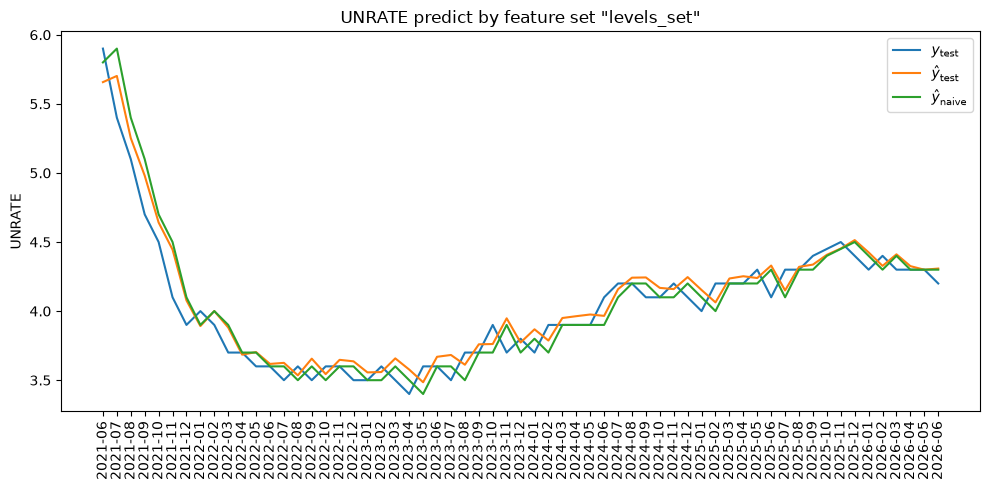

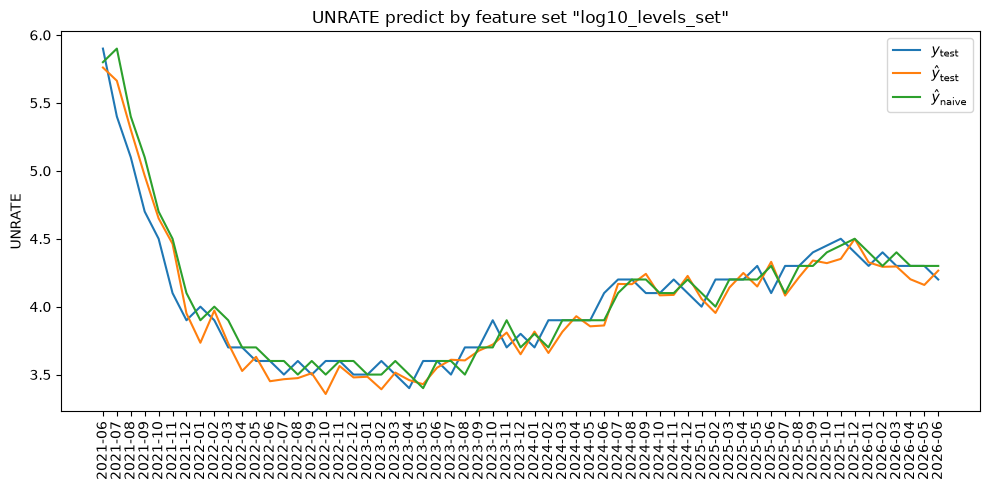

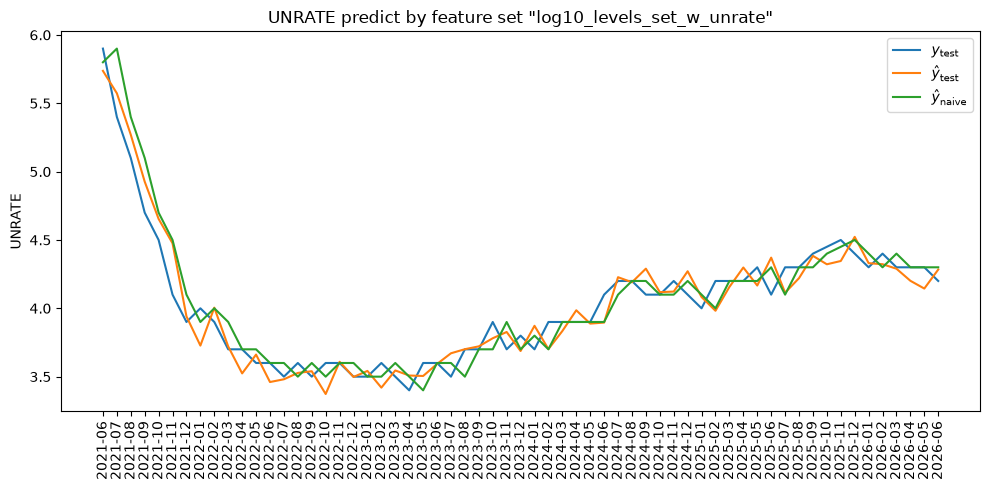

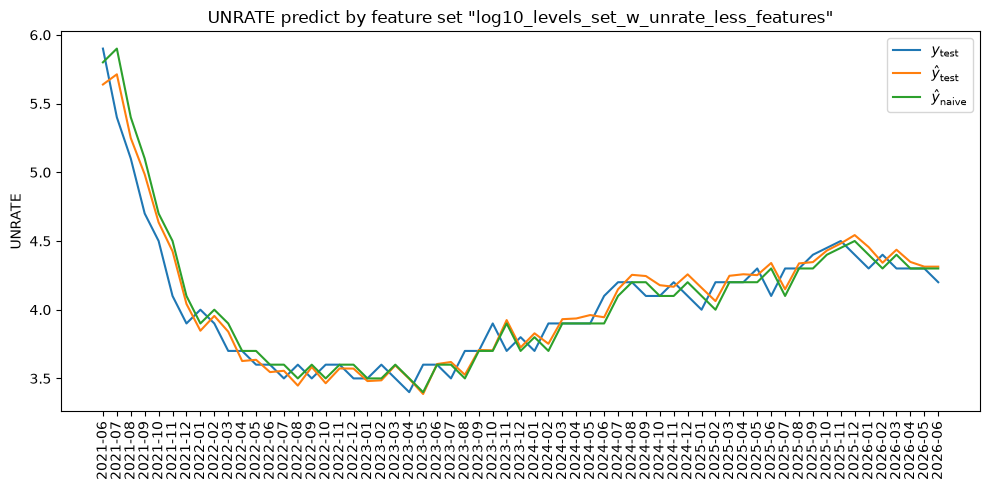

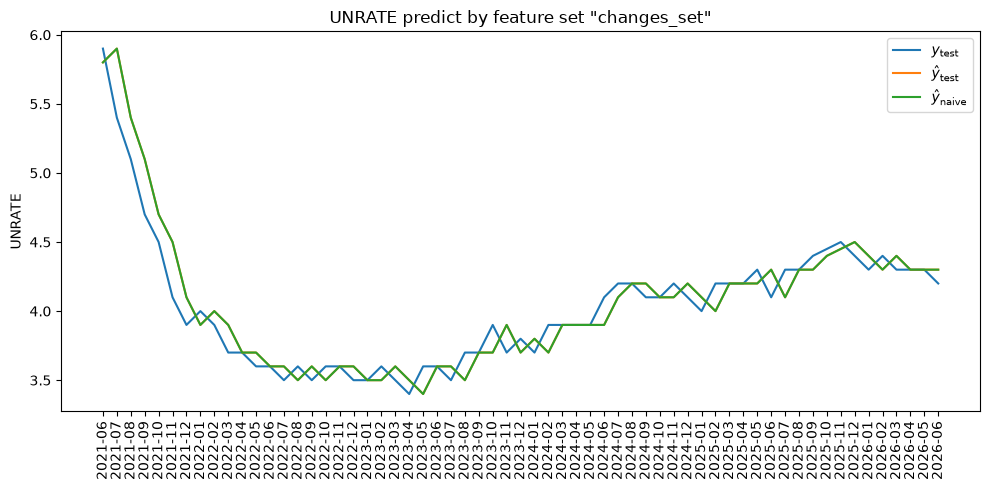

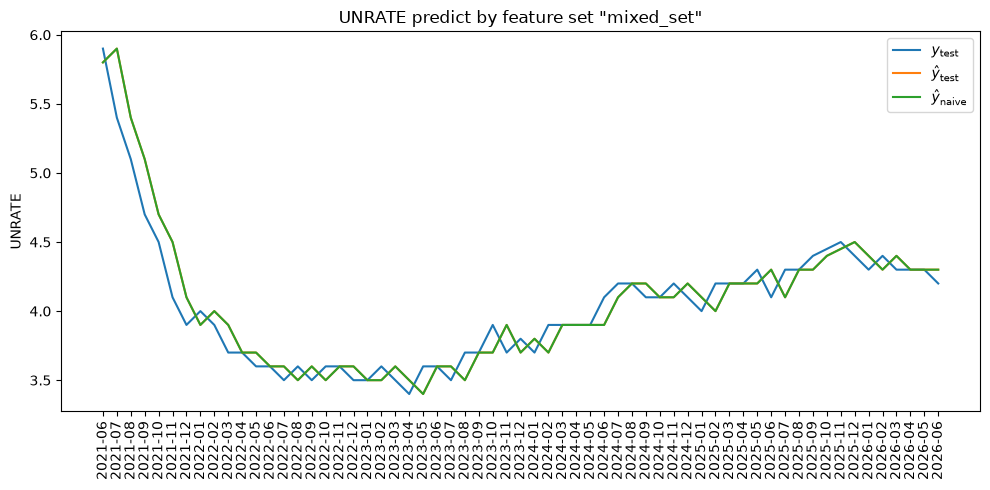

,feature_set,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement
0,levels_set,0.11063,0.111475,0.132873,0.152305,0.75822,12.758432
1,log10_levels_set,0.114799,0.111475,0.141407,0.152305,-2.981276,7.155414
2,log10_levels_set_w_unrate,0.109814,0.111475,0.135993,0.152305,1.49029,10.710188
3,log10_levels_set_w_unrate_less_features,0.109828,0.111475,0.133616,0.152305,1.478017,12.27048
4,changes_set,0.111475,0.111475,0.152305,0.152305,0.0,0.0
5,mixed_set,0.111475,0.111475,0.152305,0.152305,0.0,0.0


In [22]:
feature_set_tester(plot_results=True)

# Test final feature selection pipeline

In [23]:
import feature_pipeline

In [24]:
feature_pipeline.get_feature_selection()

,month_year,log10_INDPRO,log10_JTSJOL,log10_UNRATE,UNRATE,UNRATE_t+1
0,2000-12,1.965397,3.706547,0.591065,3.9,4.2
1,2001-01,1.963325,3.718834,0.623249,4.2,4.2
2,2001-02,1.960487,3.707315,0.623249,4.2,4.3
3,2001-03,1.959596,3.677789,0.633468,4.3,4.4
4,2001-04,1.958034,3.664172,0.643453,4.4,4.3
...,...,...,...,...,...,...
302,2026-02,2.008286,3.840232,0.643453,4.4,4.3
303,2026-03,2.006967,3.838030,0.633468,4.3,4.3
304,2026-04,2.010383,3.879956,0.633468,4.3,4.3
305,2026-05,2.010981,3.877199,0.633468,4.3,4.2


# Experimenting

In [17]:
def ridge_regression(feature_set,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False,
                     print_details = True):

    # zero-variance guard
    def zero_variance_guard(std_values):
        if np.any(np.isclose(std_values, 0)):
            raise ValueError("At least one feature has zero or near-zero standard deviation.")

    # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
    target = "UNRATE_t+1"
    
    cols = ['month_year'] + feature_set + ['UNRATE', target]
    cols = list(dict.fromkeys(cols))  # avoids duplicate UNRATE if already in feature_set
    df_train_test = df[cols].dropna().copy()

    set_len = len(df_train_test)

    train_end = int(round(set_len * 0.60))
    validation_end = int(round(set_len * 0.80))

    X_train = df_train_test[feature_set].iloc[:train_end].to_numpy()
    X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
    X_train_full = df_train_test[feature_set].iloc[:validation_end].to_numpy()
    X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

    y_train = df_train_test[target].iloc[:train_end].to_numpy()
    y_validation = df_train_test[target].iloc[train_end:validation_end].to_numpy()
    y_train_full = df_train_test[target].iloc[:validation_end].to_numpy()
    y_test = df_train_test[target].iloc[validation_end:].to_numpy()

    # standardize with z-score
    X_train_mean = X_train.mean(axis=0)
    X_train_std = X_train.std(axis=0)
    zero_variance_guard(X_train_std)
    y_train_mean = y_train.mean()

    Z_train = (X_train - X_train_mean) / X_train_std
    Z_validation = (X_validation - X_train_mean) / X_train_std

    y_train_centered = y_train - y_train_mean

    # lambda step-wise optimization parameters

    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values

    best_lambda = None
    best_validation_rmse = np.inf

    for step in range(n_lambda_optimization_steps):

        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):

            A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
            b = Z_train.T @ y_train_centered

            beta_coeffs = np.linalg.solve(A, b)

            y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

            rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

            rmse_values[i] = rmse

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_lambda = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_validation_rmse:
            best_validation_rmse = step_best_rmse
            best_lambda = step_best_lambda

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        if print_details == True:
            print(
                f"Step {step + 1}: "
                f"lambda={step_best_lambda:.8f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )

    A_best = Z_train.T @ Z_train + best_lambda * np.eye(Z_train.shape[1])
    b_best = Z_train.T @ y_train_centered

    beta_best = np.linalg.solve(A_best, b_best)

    y_pred_validation_best = y_train_mean + Z_validation @ beta_best

    # find an optimal weighting for a better MEA due to strong naive model
    y_pred_naive_validation = df_train_test["UNRATE"].iloc[train_end:validation_end].to_numpy()

    weight_candidates = np.linspace(0, 1, 101)

    best_weight = None
    best_combined_validation_mae = np.inf

    for weight in weight_candidates:
        y_pred_combined_validation = weight * y_pred_validation_best + (1 - weight) * y_pred_naive_validation
        combined_validation_mae = np.mean(np.abs(y_validation - y_pred_combined_validation))

        if combined_validation_mae < best_combined_validation_mae:
            best_combined_validation_mae = combined_validation_mae
            best_weight = weight

    # retrain using all target observations available before the test period
    X_train_full_mean = X_train_full.mean(axis=0)
    X_train_full_std = X_train_full.std(axis=0)
    zero_variance_guard(X_train_full_std)

    y_train_full_mean = y_train_full.mean()

    Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
    Z_test = (X_test - X_train_full_mean) / X_train_full_std

    y_train_full_centered = y_train_full - y_train_full_mean

    A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
    b_final = Z_train_full.T @ y_train_full_centered

    beta_coeffs_final = np.linalg.solve(A_final,b_final)

    # evaluation on final 20% test set
    y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
    y_pred_naive = df_train_test["UNRATE"].iloc[validation_end:].to_numpy()
    # in pp
    ridge_mae = np.mean(np.abs(y_test-y_pred_test))
    naive_mae = np.mean(np.abs(y_test-y_pred_naive))
    ridge_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))
    naive_rmse = np.sqrt(np.mean((y_test - y_pred_naive) ** 2))
    # in %
    mae_improvement = (1-(ridge_mae/naive_mae))*100
    rmse_improvement = (1-(ridge_rmse/naive_rmse))*100

    df_final_test_results = pd.DataFrame({
        "forecast_origin_t": df_train_test['month_year'].iloc[validation_end :].copy(),
        "forecast_target_t+1": df_train_test['month_year'].iloc[validation_end :].copy() + 1,
        "y_pred_test_t+1": y_pred_test,
        "y_pred_naive_t+1": y_pred_naive,
        "UNRATE_t+1": df_train_test[target].iloc[validation_end :].copy(),
        "ridge_abs_error": np.abs(df_train_test[target].iloc[validation_end :].to_numpy()-y_pred_test),
        "naive_abs_error": np.abs(df_train_test[target].iloc[validation_end :].to_numpy()-y_pred_naive),
    }).reset_index(drop=True)

    if print_details == True:
        print("Best lambda:", best_lambda)
        print(f"Validation RMSE: {best_validation_rmse} pp")
        print(f"Final test ridge regression model MAE: {ridge_mae} pp")
        print(f"Final test naive model MAE: {naive_mae} pp")
        print(f"Final test ridge regression model RMSE: {ridge_rmse} pp")
        print(f"Final test naive model RMSE: {naive_rmse} pp")
        print(f"Final test MAE improvement of ridge regression over the naive model: {mae_improvement}%")
        print(f"Final test RMSE improvement of ridge regression over the naive model: {rmse_improvement}%")
    

    # actual forecasting
    y_forecast = None
    if forecast_mode :
        # fits final production model on all observations
        df_final_train = df[['month_year'] + feature_set + [target]].dropna().copy()

        X_final = df_final_train[feature_set].to_numpy()
        y_final = df_final_train[target].to_numpy()

        X_final_mean = X_final.mean(axis=0)
        X_final_std = X_final.std(axis=0)
        zero_variance_guard(X_final_std)
        y_final_mean = y_final.mean()

        Z_final = (X_final - X_final_mean) / X_final_std

        y_final_centered = y_final - y_final_mean

        A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
        b = Z_final.T @ y_final_centered

        beta_final = np.linalg.solve(A, b)

        # Latest complete feature observation
        df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

        X_forecast = df_forecast[feature_set].to_numpy()
        Z_forecast = (X_forecast - X_final_mean) / X_final_std
        y_forecast = (y_final_mean + Z_forecast @ beta_final).item()

    return (best_lambda,
            best_validation_rmse,
            ridge_mae,
            naive_mae,
            ridge_rmse,
            naive_rmse,
            mae_improvement,
            rmse_improvement,
            df_final_test_results,
            y_forecast)

In [18]:
def ridge_regression(feature_set,
                     horizon,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False):
    if horizon not in [1, 3, 6, 12]:
        raise ValueError(
            f"horizon must currently be 1, 3, 6, or 12 months. "
            f"Received {horizon}."
        )

    # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
    target_horizon = f"UNRATE_t+{horizon}"
    df_train_test = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

    set_len = len(df_train_test)

    train_end = int(round(set_len * 0.60))
    validation_end = int(round(set_len * 0.80))
    
    # prevent time-series leakage
    train_fit_end = train_end - horizon + 1
    train_full_fit_end = validation_end - horizon + 1

    if train_fit_end <= 0 or train_full_fit_end <= 0:
        raise ValueError(
            "Not enough observations for the selected forecast horizon."
        )

    X_train = df_train_test[feature_set].iloc[:train_fit_end].to_numpy()
    X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
    X_train_full = df_train_test[feature_set].iloc[:train_full_fit_end].to_numpy()
    X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

    y_train = df_train_test[target_horizon].iloc[:train_fit_end].to_numpy()
    y_validation = df_train_test[target_horizon].iloc[train_end:validation_end].to_numpy()
    y_train_full = df_train_test[target_horizon].iloc[:train_full_fit_end].to_numpy()
    y_test = df_train_test[target_horizon].iloc[validation_end:].to_numpy()

    # standardize with z-score
    X_train_mean = X_train.mean(axis=0)
    X_train_std = X_train.std(axis=0)
    y_train_mean = y_train.mean()

    Z_train = (X_train - X_train_mean) / X_train_std
    Z_validation = (X_validation - X_train_mean) / X_train_std

    y_train_centered = y_train - y_train_mean

    # lambda step-wise optimization parameters
    # n_lambda_candidates = 50
    # n_lambda_optimization_steps = 6

    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
    # lower_lambda = 1e-6
    # upper_lambda = 1e4

    best_lambda = None
    best_validation_rmse = np.inf

    for step in range(n_lambda_optimization_steps):

        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):

            A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
            b = Z_train.T @ y_train_centered

            beta_coeffs = np.linalg.solve(A, b)

            y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

            rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

            rmse_values[i] = rmse

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_lambda = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_validation_rmse:
            best_validation_rmse = step_best_rmse
            best_lambda = step_best_lambda

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        print(
            f"Step {step + 1}: "
            f"lambda={step_best_lambda:.8f}, "
            f"validation RMSE={step_best_rmse:.6f}"
        )


    # retrain using all target observations available before the test period
    X_train_full_mean = X_train_full.mean(axis=0)
    X_train_full_std = X_train_full.std(axis=0)

    y_train_full_mean = y_train_full.mean()

    Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
    Z_test = (X_test - X_train_full_mean) / X_train_full_std

    y_train_full_centered = y_train_full - y_train_full_mean

    A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
    b_final = Z_train_full.T @ y_train_full_centered

    beta_coeffs_final = np.linalg.solve(A_final,b_final)

    # evaluation on final 20% test set
    y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
    test_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

    df_final_test_results = pd.DataFrame({
        "forecast_origin": df_train_test['month_year'].iloc[validation_end :].copy(),
        "forecast_target": df_train_test['month_year'].iloc[validation_end :].copy() + horizon,
        "y_pred_test": y_pred_test,
        "UNRATE": df_train_test[target_horizon].iloc[validation_end :].copy()
    }).reset_index(drop=True)

    # df_80pct_test_results = df_train_test[['month_year'] + [target_horizon]].iloc[validation_end:].dropna().copy().rename(columns={target_horizon:'UNRATE'})
    # df_80pct_test_results['month_year'] = df_80pct_test_results['month_year'] + horizon
    # df_80pct_test_results['y_pred_test'] = y_pred_test

    print("Best lambda:", best_lambda)
    print("Validation RMSE:", best_validation_rmse)
    print("Final test RMSE:", test_rmse)

    # actual forecasting
    y_forecast = None
    if forecast_mode :
        # fits final production model on all observations
        df_final_train = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

        X_final = df_final_train[feature_set].to_numpy()
        y_final = df_final_train[target_horizon].to_numpy()

        X_final_mean = X_final.mean(axis=0)
        X_final_std = X_final.std(axis=0)
        y_final_mean = y_final.mean()

        Z_final = (X_final - X_final_mean) / X_final_std

        y_final_centered = y_final - y_final_mean

        A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
        b = Z_final.T @ y_final_centered

        beta_final = np.linalg.solve(A, b)

        # Latest complete feature observation
        df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

        X_forecast = (df_forecast[feature_set].to_numpy())
        Z_forecast = (X_forecast - X_final_mean) / X_final_std
        y_forecast = (y_final_mean + Z_forecast @ beta_final).item()

    return best_lambda, best_validation_rmse, test_rmse, df_final_test_results, y_forecast

In [19]:
def ridge_regression(feature_set,
                     horizon,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False):
    if horizon in [1,3,6,12]:
        # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
        target_horizon = f"UNRATE_t+{horizon}"
        df_train_test = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

        set_len = len(df_train_test)

        train_end = int(round(set_len * 0.60))
        validation_end = int(round(set_len * 0.80))

        X_train = df_train_test[feature_set].iloc[:train_end].to_numpy()
        X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
        X_train_full = df_train_test[feature_set].iloc[:validation_end].to_numpy()
        X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

        y_train = df_train_test[target_horizon].iloc[:train_end].to_numpy()
        y_validation = df_train_test[target_horizon].iloc[train_end:validation_end].to_numpy()
        y_train_full = df_train_test[target_horizon].iloc[:validation_end].to_numpy()
        y_test = df_train_test[target_horizon].iloc[validation_end:].to_numpy()

        # standardize with z-score
        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)
        y_train_mean = y_train.mean()

        Z_train = (X_train - X_train_mean) / X_train_std
        Z_validation = (X_validation - X_train_mean) / X_train_std

        y_train_centered = y_train - y_train_mean

        # lambda step-wise optimization parameters
        # n_lambda_candidates = 50
        # n_lambda_optimization_steps = 6

        # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
        # lower_lambda = 1e-6
        # upper_lambda = 1e4

        best_lambda = None
        best_validation_rmse = np.inf

        for step in range(n_lambda_optimization_steps):

            lambda_space = np.geomspace(
                lower_lambda,
                upper_lambda,
                n_lambda_candidates
            )

            rmse_values = np.empty(len(lambda_space))

            for i, penalty_param in enumerate(lambda_space):

                A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
                b = Z_train.T @ y_train_centered

                beta_coeffs = np.linalg.solve(A, b)

                y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

                rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

                rmse_values[i] = rmse

            # pos of best lambda in current search
            best_pos = np.argmin(rmse_values)

            step_best_lambda = lambda_space[best_pos]
            step_best_rmse = rmse_values[best_pos]

            # store best result found overall
            if step_best_rmse < best_validation_rmse:
                best_validation_rmse = step_best_rmse
                best_lambda = step_best_lambda

            # refine around the best lambda
            lower_pos = max(best_pos - 1, 0)
            upper_pos = min(best_pos + 1, len(lambda_space) - 1)

            lower_lambda = lambda_space[lower_pos]
            upper_lambda = lambda_space[upper_pos]

            print(
                f"Step {step + 1}: "
                f"lambda={step_best_lambda:.8f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )


        # train on full 80% training set
        X_train_full_mean = X_train_full.mean(axis=0)
        X_train_full_std = X_train_full.std(axis=0)

        y_train_full_mean = y_train_full.mean()

        Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
        Z_test = (X_test - X_train_full_mean) / X_train_full_std

        y_train_full_centered = y_train_full - y_train_full_mean

        A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
        b_final = Z_train_full.T @ y_train_full_centered

        beta_coeffs_final = np.linalg.solve(A_final,b_final)

        # evaluation on full 80% training set
        y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
        test_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

        df_80pct_test_results = df_train_test[['month_year'] + [target_horizon]].iloc[validation_end:].dropna().copy().rename(columns={target_horizon:'UNRATE'})
        df_80pct_test_results['month_year'] = df_80pct_test_results['month_year'] + horizon
        df_80pct_test_results['y_pred_test'] = y_pred_test

        print("Best lambda:", best_lambda)
        print("Validation RMSE:", best_validation_rmse)
        print("Final test RMSE:", test_rmse)

        # actual forecasting
        y_forecast = None
        if forecast_mode == True:
            # fits final production model on all observations
            df_final_train = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

            X_final = df_final_train[feature_set].to_numpy()
            y_final = df_final_train[target_horizon].to_numpy()

            X_final_mean = X_final.mean(axis=0)
            X_final_std = X_final.std(axis=0)
            y_final_mean = y_final.mean()

            Z_final = (X_final - X_final_mean) / X_final_std

            y_final_centered = y_final - y_final_mean

            A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
            b = Z_final.T @ y_final_centered

            beta_final = np.linalg.solve(A, b)

            # Latest complete feature observation
            df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

            X_forecast = (df_forecast[feature_set].to_numpy())
            Z_forecast = (X_forecast - X_final_mean) / X_final_std
            y_forecast = y_final_mean + Z_forecast @ beta_final

        return best_lambda, best_validation_rmse, test_rmse, df_80pct_test_results, y_forecast

    if not 1 <= horizon <= 12:
        raise ValueError(
            f"horizon must be between 1 and 12 months. "
            f"Received {horizon}."
        )

In [20]:
split_idx = int(len(df_train_test[feature_set])*0.8)
X_training = df_train_test[feature_set].iloc[:split_idx].to_numpy()
X_test = df_train_test[feature_set].iloc[split_idx:].to_numpy()

y_training = df_train_test[target_horizon].iloc[:split_idx].to_numpy()
y_test = df_train_test[target_horizon].iloc[split_idx:].to_numpy()

means_X_training = X_training.mean(axis=0)
stdevs_X_training = X_training.std(axis=0)

# mean_y_training is also \hat{beta}_0 
mean_y_training = y_training.mean()

# z-score standardized X features and target matrix
Z_training = (X_training - means_X_training)/stdevs_X_training
Z_test = (X_test - means_X_training)/stdevs_X_training
# X will be actual data to predict on
# Z = (X - means_X_training)/stdevs_X_training 

y_training_centered = y_training - mean_y_training

# lambda = penalty_param, @ shorthand for np.matmul(), arr.T shorthand for arr.transpose()
penalty_param = 1e-06

A = Z_training.T @ Z_training + penalty_param * np.identity(X_training.shape[1])
b = Z_training.T @ y_training_centered

beta_coeffs = np.linalg.solve(A,b)

y_pred = mean_y_training + Z_test @ beta_coeffs # Z_test to test and Z for actual data

NameError: name 'df_train_test' is not defined

In [ ]:
print(int(len(df_train_test[feature_set])))
print(int(len(df_train_test[feature_set])*0.6))
print(int(len(df_train_test[feature_set])*0.2))
print(int(len(df_train_test[feature_set])*0.2))

294
176
58
58


In [ ]:
round(len(df_train_test[feature_set])*0.6)

176

In [ ]:
np.array([len(df_train_test[feature_set])*0.6,len(df_train_test[feature_set])*0.2,len(df_train_test[feature_set])*0.2]).round().astype('int')

array([176,  59,  59])

In [ ]:
set_len = len(df_train_test[feature_set])
train_validate_test_idxs = np.array([set_len*0.6, set_len*0.8, set_len]).round().astype('int')

X_train_validate = df_train_test[feature_set].iloc[:train_validate_test_idxs[0]]
X_train_full = df_train_test[feature_set].iloc[: train_validate_test_idxs[1]]
X_test_validate = df_train_test[feature_set].iloc[train_validate_test_idxs[0]:train_validate_test_idxs[1]]
X_test_full = df_train_test[feature_set].iloc[train_validate_test_idxs[1]:]

y_train_validate = df_train_test[target_horizon].iloc[:train_validate_test_idxs[0]]
y_train_full = df_train_test[target_horizon].iloc[: train_validate_test_idxs[1]]
y_test_validate = df_train_test[target_horizon].iloc[train_validate_test_idxs[0]:train_validate_test_idxs[1]]
y_test_full = df_train_test[target_horizon].iloc[train_validate_test_idxs[1]:]

X_train_validate_means = X_train_validate.mean(axis=0)
X_train_full_means = X_train_full.mean(axis=0)
X_train_validate_stds = X_train_validate.std(axis=0)
X_train_full_stds = X_train_full.std(axis=0)

# aka \hat{\beta}_0
y_train_validate_mean = y_train_validate.mean()
y_train_full_mean = y_train_full.mean()

# z-score standardization
Z_train_validate = (X_train_validate - X_train_validate_means) / X_train_validate_stds
Z_train_full = (X_train_full - X_train_full_means) / X_train_full_stds
Z_test_validate = (X_test_validate - X_train_validate_means) / X_train_validate_stds
Z_test_full = (X_test_full - X_train_full_means) / X_train_full_stds

y_train_validate_centered = y_train_validate - y_train_validate_mean
y_train_full_centered = y_train_full - y_train_full_mean

# optimizing lambda (penalty_param)
min_max_lambda = np.array([1e-5, 1e5])
lambda_step_ranges = np.array([min_max_lambda])
lambda_space_subdivs = X_test_validate.shape[0]
optimization_steps = range(10)
rmse_collector = np.array([[np.inf, np.inf]])

for step in optimization_steps:
    lambda_space = np.geomspace(lambda_step_ranges[step][0], lambda_step_ranges[step][1], lambda_space_subdivs)
    temp_lambda = np.array([])
    temp_rmse = np.array([])

    for penalty_param in lambda_space:
        A = Z_train_validate.T @ Z_train_validate + penalty_param * np.eye(Z_train_validate.shape[1])
        b = Z_train_validate.T @ y_train_validate_centered
        beta_coeffs = np.linalg.solve(A,b)

        y_pred = y_train_validate_mean + Z_test_validate @ beta_coeffs

        rmse = np.sqrt(np.mean((y_test_validate - y_pred) ** 2))

        temp_lambda = np.append(temp_lambda, penalty_param)
        temp_rmse = np.append(temp_rmse, rmse)

    # adds two best lambda and rmse combos for next optimization step's lambda interval
    lambda_step_ranges = np.append(lambda_step_ranges, [temp_lambda[temp_rmse.argpartition(2)[:2]]], axis=0)
    rmse_collector = np.append(rmse_collector, [temp_rmse[temp_rmse.argpartition(2)[:2]]], axis=0)

rmse_collector


array([[       inf,        inf],
       [1.77927857, 1.7792786 ],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857]])

In [ ]:
lambda_step_ranges

array([[-5,  5]])

In [ ]:
arr = np.array([])

In [ ]:
arr = np.append(arr, 1.2)
arr

array([1. , 1.4, 1.8, 0.8, 0.2, 1.4, 1.2])

In [ ]:
lambda_step_ranges = np.append(lambda_step_ranges, [arr[arr.argpartition(2)[:2]]], axis=0)

In [ ]:
lambda_step_ranges[0]

array([-5.,  5.])

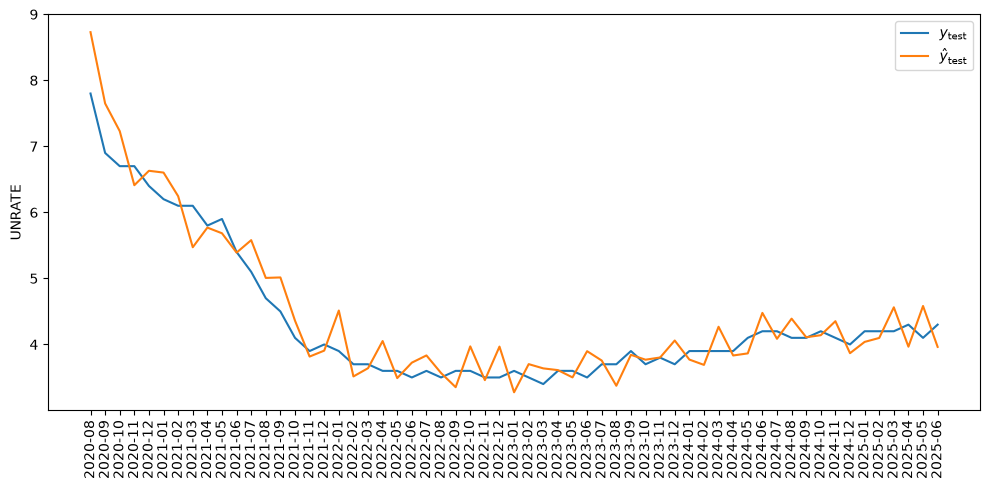

In [ ]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(df_train_test['month_year'].iloc[split_idx:].dt.strftime("%Y-%m"), df_train_test[target_horizon].iloc[split_idx:], label=r"$y_{\text{test}}$")
ax.plot(df_train_test['month_year'].iloc[split_idx:].dt.strftime("%Y-%m"), y_pred, label=r"$\hat{y}_{\text{test}}$")
ax.tick_params("x", rotation=90, rotation_mode="xtick")
ax.set_ylabel("UNRATE")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
rmse

np.float64(0.3204423859870104)

In [ ]:
def feature_set_tester(keys=sets.keys(), plot_results=True):
    df_feature_set_comp = pd.DataFrame(columns=["feature_set",
                                                "ridge_mae",
                                                "naive_mae",
                                                "ridge_rmse",
                                                "naive_rmse",
                                                "combined_mae_improvement",
                                                "rcombined_mse_improvement"])
    for key in keys:
        (
        best_lambda,
        best_validation_rmse,
        best_weight,
        best_combined_validation_mae,
        ridge_mae,
        naive_mae,
        combined_mae,
        ridge_rmse,
        naive_rmse,
        combined_rmse,
        ridge_mae_improvement,
        combined_mae_improvement,
        ridge_rmse_improvement,
        combined_rmse_improvement,
        df_final_test_results,
        y_forecast_ridge,
        y_forecast_naive,
        y_forecast_combined) = ridge_regression(feature_set=sets[key], forecast_mode=False, print_details=False)

        new_row = pd.DataFrame([
            dict(zip(df_feature_set_comp.columns.to_list(), [key, combined_mae, naive_mae, combined_rmse, naive_rmse, combined_mae_improvement, combined_rmse_improvement]))
        ])
        df_feature_set_comp = pd.concat([df_feature_set_comp, new_row], ignore_index=True, axis=0)

        if plot_results == True:
            fig, ax = plt.subplots(figsize=(10,5))
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['UNRATE_t+1'], label=r"$y_{\text{test}}$")
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['y_pred_combined_t+1'], label=r"$\hat{y}_{\text{test}}$")
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['y_pred_naive_t+1'], label=r"$\hat{y}_{\text{naive}}$")
            ax.tick_params("x", rotation=90, rotation_mode="xtick")
            ax.set_ylabel("UNRATE")
            ax.set_title(f'UNRATE predict by feature set "{key}"')
            ax.legend()
            plt.tight_layout()
            plt.show()    

    return df_feature_set_comp

